## Import Libraries

In [1]:
import sys

print("Python executable:", sys.executable)

import pandas
import sklearn
import imblearn

print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)


Python executable: C:\Users\HP\Desktop\Customers-Churn-Prediction\.venv\Scripts\python.exe
Pandas: 3.0.6
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2


In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    RandomizedSearchCV, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, precision_recall_curve
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

RANDOM_STATE = 42

from pathlib import Path

## Load dataset

In [3]:
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place WA_Fn-UseC_-Telco-Customer-Churn.csv beside this notebook "
        "or update DATA_PATH to the correct file location."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Inspect and Validate dataset

In [4]:
print("Columns:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nExact duplicate rows:", df.duplicated().sum())

if "Churn" not in df.columns:
    raise ValueError("Expected target column 'Churn' was not found.")

print("\nTarget labels:")
print(df["Churn"].value_counts(dropna=False))

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity  

,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Exact duplicate rows: 0

Target labels:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## Clean the Data

In [5]:
df = df.copy()

# Remove exact duplicate rows, if any
df = df.drop_duplicates().copy()

# Telco dataset commonly stores TotalCharges as text; blank values become NaN
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Remove rows with missing/unknown target labels
df = df[df["Churn"].isin(["Yes", "No"])].copy()

# customerID is an identifier, not a predictive feature
if "customerID" in df.columns:
    df = df.drop_duplicates(subset=["customerID"]).copy()

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Shape after cleaning: (7043, 21)
Missing values after cleaning:


,missing_count
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


## EDA

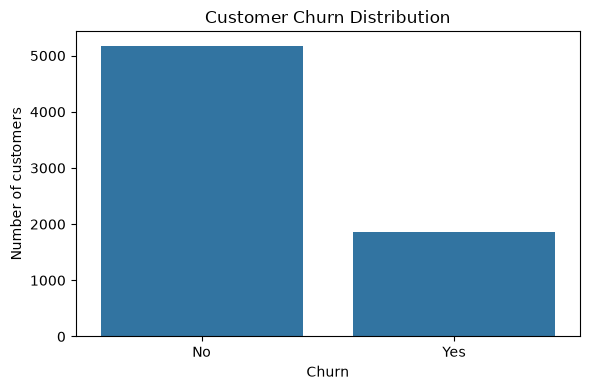

Target distribution (%):


,percentage
Churn,
No,73.46
Yes,26.54


In [6]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Churn")
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

churn_percent = (df["Churn"].value_counts(normalize=True) * 100).round(2)
print("Target distribution (%):")
display(churn_percent.to_frame("percentage"))

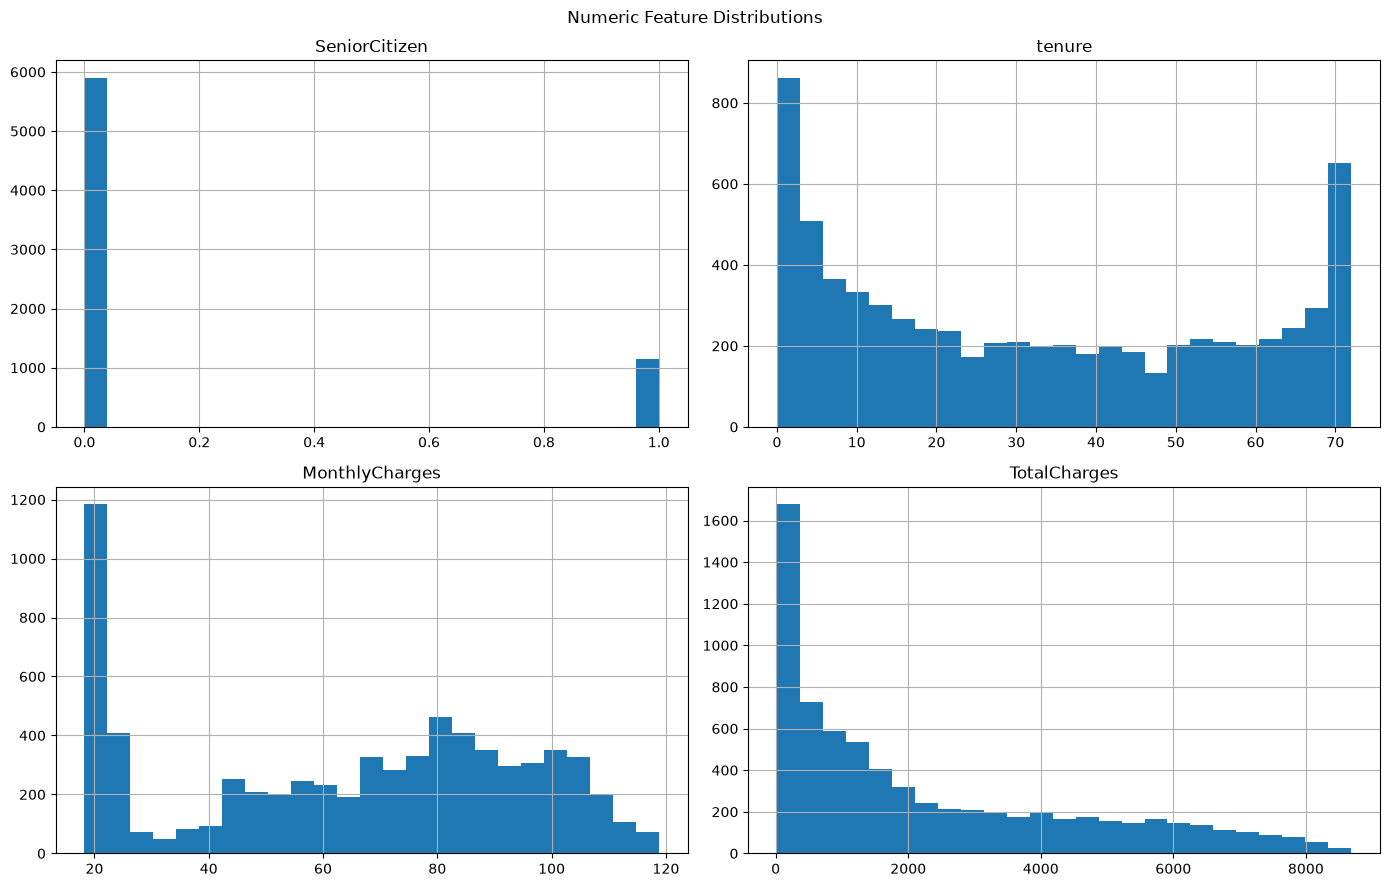

In [7]:
# Numeric feature distributions
numeric_for_eda = df.select_dtypes(include=np.number).columns.tolist()
if numeric_for_eda:
    df[numeric_for_eda].hist(figsize=(14, 9), bins=25)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()

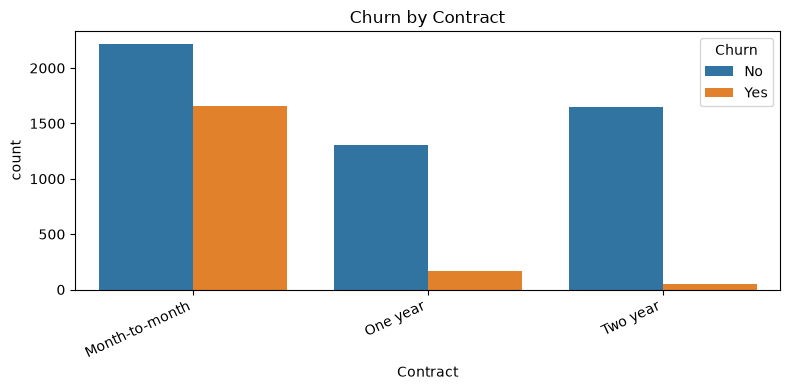

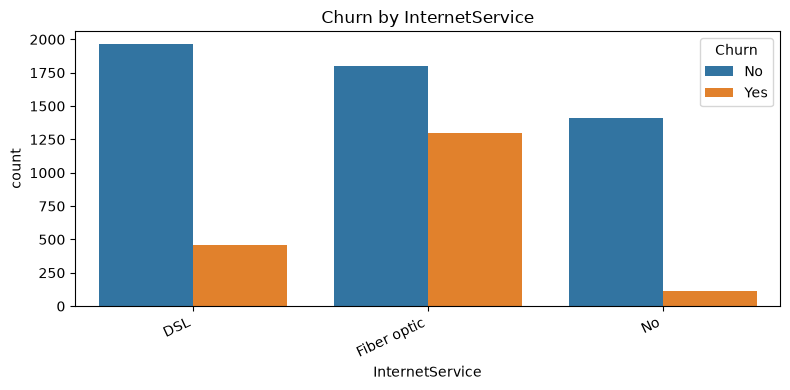

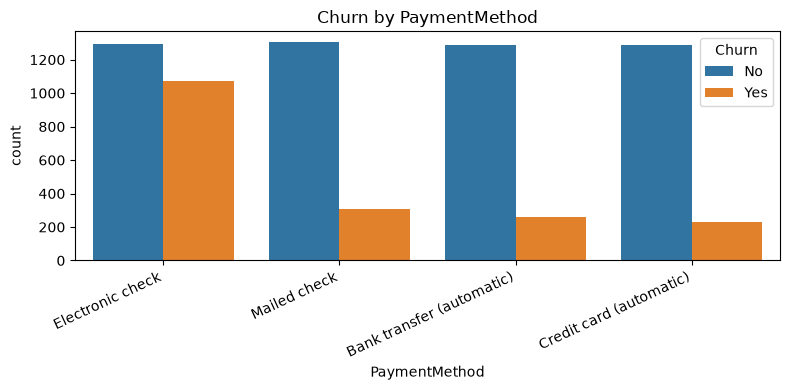

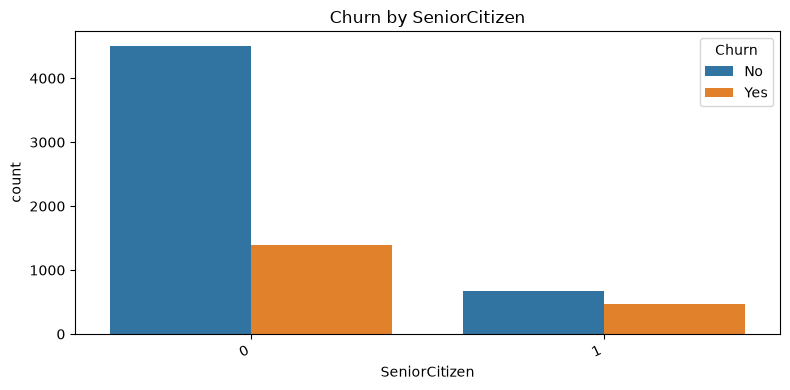

In [8]:
# Churn by common categorical features, if present
eda_columns = [c for c in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"] if c in df.columns]
for col in eda_columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue="Churn")
    plt.title(f"Churn by {col}")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## Create features and Split the data

In [9]:
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

if y.isna().any():
    raise ValueError("Unexpected values found in Churn. Check target labels.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining target counts:")
display(y_train.value_counts().rename(index={0: "Stayed (No)", 1: "Churned (Yes)"}).to_frame("count"))
print("\nTest target counts (not balanced):")
display(y_test.value_counts().rename(index={0: "Stayed (No)", 1: "Churned (Yes)"}).to_frame("count"))

Training shape: (5634, 19)
Test shape: (1409, 19)

Training target counts:


,count
Churn,
Stayed (No),4139
Churned (Yes),1495



Test target counts (not balanced):


,count
Churn,
Stayed (No),1035
Churned (Yes),374


## Build preprocessing pipeline

In [10]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Compare Logistic Regression with and without Oversampling

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

comparison_models = {
    "Logistic Regression (no oversampling)": Pipeline(steps=[
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Logistic Regression (RandomOverSampler)": ImbPipeline(steps=[
        ("preprocess", clone(preprocessor)),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

balance_results = []
for name, estimator in comparison_models.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1
    )
    row = {"Model": name}
    for metric in scoring:
        row[f"CV {metric}"] = scores[f"test_{metric}"].mean()
    balance_results.append(row)

balance_comparison = pd.DataFrame(balance_results).sort_values(
    "CV roc_auc", ascending=False
)
display(balance_comparison.round(4))

,Model,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,CV average_precision
0,Logistic Regression (no oversampling),0.8021,0.6529,0.5431,0.5923,0.8461,0.6614
1,Logistic Regression (RandomOverSampler),0.7483,0.5166,0.8020,0.6282,0.8457,0.6583


##  Tune models using RandomOverSampler

In [12]:
tuning_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

model_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10, 100]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "model__n_estimators": [150, 250, 350],
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.8]
        }
    ),
    "Extra Trees": (
        ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            "model__n_estimators": [150, 250, 350],
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.8]
        }
    )
}

tuning_results = []
best_models = {}
search_objects = {}

for name, (estimator, param_distributions) in model_spaces.items():
    pipeline = ImbPipeline(steps=[
        ("preprocess", clone(preprocessor)),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", estimator)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=8,
        scoring="roc_auc",
        cv=tuning_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    print(f"\nTuning {name}...")
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    search_objects[name] = search
    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best parameters": search.best_params_
    })

tuning_results_df = pd.DataFrame(tuning_results).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)

display(tuning_results_df)
best_model_name = tuning_results_df.loc[0, "Model"]
best_model = best_models[best_model_name]

print("Selected model:", best_model_name)
print("Best CV ROC-AUC:", round(float(tuning_results_df.loc[0, "Best CV ROC-AUC"]), 4))


Tuning Logistic Regression...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Tuning Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Tuning Extra Trees...
Fitting 3 folds for each of 8 candidates, totalling 24 fits


,Model,Best CV ROC-AUC,Best parameters
0,Logistic Regression,0.845320,{'model__C': 100}
1,Random Forest,0.839646,"{'model__n_estimators': 350, 'model__min_sampl..."
2,Extra Trees,0.828776,"{'model__n_estimators': 350, 'model__min_sampl..."


Selected model: Logistic Regression
Best CV ROC-AUC: 0.8453


##  Select a decision threshold using training data only

In [13]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, f1_score
import numpy as np

# Split training data into model-training and threshold-validation sets
X_fit, X_threshold, y_fit, y_threshold = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

# Clone the selected model pipeline
threshold_model = clone(best_model)

# Fit using only the model-training subset
threshold_model.fit(X_fit, y_fit)

# Get churn probabilities on the validation subset
y_prob_threshold = threshold_model.predict_proba(X_threshold)[:, 1]

# Find the threshold that maximizes F1
precision, recall, thresholds = precision_recall_curve(
    y_threshold,
    y_prob_threshold
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
best_threshold = float(thresholds[best_idx])

print("Selected threshold:", best_threshold)
print("Validation F1:", f1_scores[best_idx])


Selected threshold: 0.6021631210539248
Validation F1: 0.6465256797578127


##  Final evaluation on the untouched test set

Selected model: LogisticRegression

Decision threshold selected using training data: 0.6021631210539248


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Default threshold (0.50),0.7331,0.4983,0.7888,0.6108,0.8409,0.6255
1,Tuned threshold (0.6022),0.7679,0.5489,0.7059,0.6175,0.8409,0.6255



Classification Report (Tuned Threshold):
              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



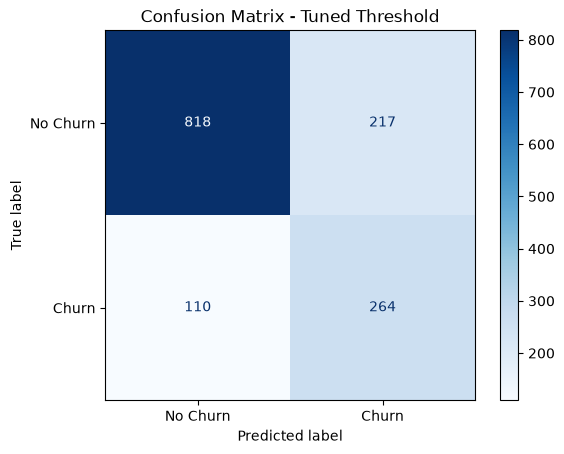

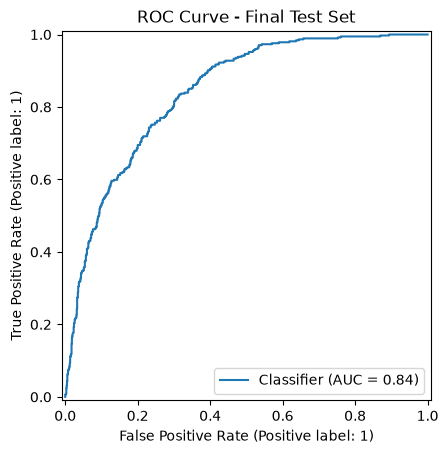

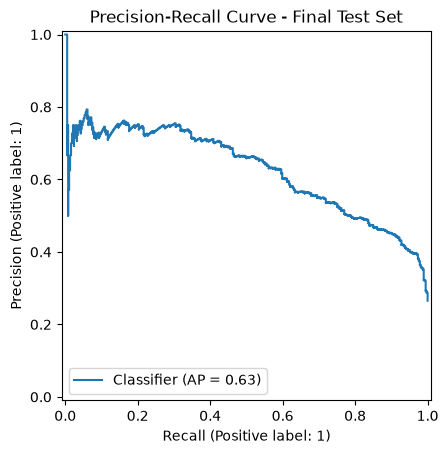

In [14]:

# Final evaluation on the untouched test set

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# 1. Train the selected pipeline on the complete training set
best_model.fit(X_train, y_train)

# 2. Predict probabilities on the untouched test set
y_test_prob = best_model.predict_proba(X_test)[:, 1]

# 3. Predictions using the default threshold (0.50)
y_pred_default = (y_test_prob >= 0.50).astype(int)

# 4. Predictions using the threshold selected in Fix 2
y_pred_tuned = (y_test_prob >= best_threshold).astype(int)

# 5. Evaluation function
def evaluate_model(y_true, y_pred, y_prob, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    }

# 6. Compare both thresholds
results = pd.DataFrame([
    evaluate_model(
        y_test, y_pred_default, y_test_prob, "Default threshold (0.50)"
    ),
    evaluate_model(
        y_test, y_pred_tuned, y_test_prob,
        f"Tuned threshold ({best_threshold:.4f})"
    )
])

print("Selected model:", type(best_model.named_steps[
    list(best_model.named_steps.keys())[-1]
]).__name__ if hasattr(best_model, "named_steps") else type(best_model).__name__)

print("\nDecision threshold selected using training data:", best_threshold)
display(results.round(4))

# 7. Detailed report for the tuned threshold
print("\nClassification Report (Tuned Threshold):")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# 8. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("Confusion Matrix - Tuned Threshold")
plt.show()

# 9. ROC curve
RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title("ROC Curve - Final Test Set")
plt.show()

# 10. Precision-Recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_test_prob)
plt.title("Precision-Recall Curve - Final Test Set")
plt.show()


## Feature importance (permutation importance)

,Feature,Importance mean,Importance std
4,tenure,0.185601,0.004783
7,InternetService,0.167778,0.018800
17,MonthlyCharges,0.146871,0.014294
14,Contract,0.036222,0.003134
13,StreamingMovies,0.033846,0.004859
12,StreamingTV,0.031153,0.005290
18,TotalCharges,0.017042,0.002509
6,MultipleLines,0.014544,0.002989
10,DeviceProtection,0.013593,0.003857
9,OnlineBackup,0.013541,0.002797


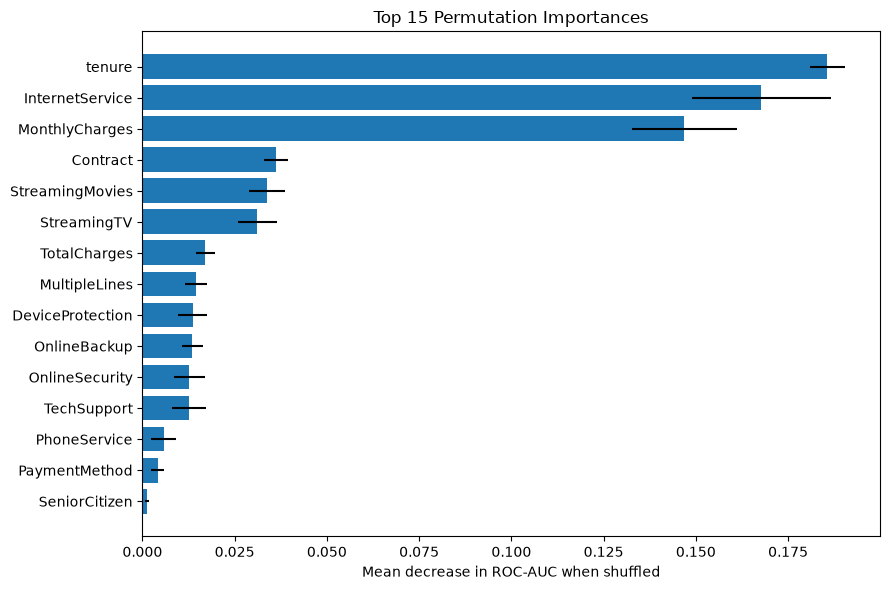

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance mean": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance mean")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance mean"], xerr=top_features["Importance std"])
plt.xlabel("Mean decrease in ROC-AUC when shuffled")
plt.title("Top 15 Permutation Importances")
plt.tight_layout()
plt.show()

##  Save and reload the trained model

In [16]:
import joblib

# Save trained model
joblib.dump(best_model, "best_model.joblib")

# Save threshold in metadata
metadata = {
    "decision_threshold": float(best_threshold)
}
joblib.dump(metadata, "model_metadata.joblib")

# Reload model and metadata
loaded_model = joblib.load("best_model.joblib")
loaded_metadata = joblib.load("model_metadata.joblib")

loaded_threshold = loaded_metadata["decision_threshold"]

print("Model and threshold loaded successfully!")
print("Decision threshold:", loaded_threshold)

Model and threshold loaded successfully!
Decision threshold: 0.6021631210539248


##  Verify the saved model with sample records

In [17]:
## Verify the saved model with sample records

import joblib
import pandas as pd
import numpy as np

# 1. Load the saved model
loaded_model = joblib.load("best_model.joblib")

# 2. Load saved metadata and decision threshold
loaded_metadata = joblib.load("model_metadata.joblib")
loaded_threshold = loaded_metadata["decision_threshold"]

print("Model loaded successfully!")
print("Decision threshold:", round(loaded_threshold, 4))

# 3. Select sample records from the test dataset
# X_test must already exist from your earlier notebook cells
sample_records = X_test.head(5).copy()

# 4. Predict churn probabilities using the saved model
churn_probabilities = loaded_model.predict_proba(sample_records)[:, 1]

# 5. Apply the saved decision threshold
churn_predictions = (
    churn_probabilities >= loaded_threshold
).astype(int)

# 6. Display the results
results = pd.DataFrame({
    "Churn Probability": churn_probabilities,
    "Predicted Churn": churn_predictions,
    "Prediction": [
        "Churn" if prediction == 1 else "No Churn"
        for prediction in churn_predictions
    ]
}, index=sample_records.index)

print("\nSample Prediction Results:")
display(results.round(4))

# 7. Verify prediction output
assert len(churn_predictions) == len(sample_records)
assert np.isin(churn_predictions, [0, 1]).all()

print("\nVerification successful!")
print("The saved model generated predictions correctly.")

Model loaded successfully!
Decision threshold: 0.6022

Sample Prediction Results:


,Churn Probability,Predicted Churn,Prediction
437,0.1410,0,No Churn
2280,0.8530,1,Churn
2235,0.1286,0,No Churn
4460,0.6758,1,Churn
3761,0.0708,0,No Churn



Verification successful!
The saved model generated predictions correctly.


## Deployment notes

- Use `best_model.joblib` and `model_metadata.joblib` in your app.
- Send new customer data with the same feature names and compatible data types as `X_train`.
- Do not include `Churn` or `customerID` in model input.
- Use the saved `decision_threshold` from `model_metadata.joblib` when converting probabilities into predictions.
- Keep the CSV training data private if it contains customer information.
- Retrain and re-evaluate if the customer population or data schema changes.
- Report actual evaluation metrics from your completed run; do not claim improvement without evidence.